# Análisis Exploratorio de Datos: Transacciones con Tarjeta

Este notebook explora el conjunto de datos que alimentará el modelo de riesgo del servidor MCP de monitoreo de fraude. **No se entrena ningún modelo aquí.** El objetivo es averiguar qué contiene el conjunto de datos, para decidir con evidencia, cómo deben transformarse antes de entrenar.

## 1. Objetivo y datos

Se utiliza el *Credit Card Transactions Fraud Detection Dataset* de Kartik Shenoy en Kaggle (2020), un conjunto de transacciones **sintéticas** (ningún dato corresponde a personas reales). Viene partido en dos archivos por fecha:

| Archivo | Contenido |
|---|---|
| `data/raw/fraudTrain.csv` | transacciones de enero 2019 a junio 2020 |
| `data/raw/fraudTest.csv` | transacciones de junio 2020 a diciembre 2020 |

Cada fila es una transacción con tarjeta: cuándo ocurrió, qué tarjeta se usó, en qué comercio, por cuánto, y dónde están el titular y el comercio. La columna `is_fraud` vale `1` si la transacción fue fraudulenta y `0` si fue legítima; es la variable que el modelo aprenderá a predecir.

La exploración se hace **solo sobre el archivo de entrenamiento**. El de prueba se reserva para evaluar el modelo más adelante; si se explorara ahora, las decisiones quedarían contaminadas por datos que deben permanecer sin ver.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("..") / "data" / "raw"

# Paleta: azul = legítima, rojo = fraude.
AZUL, ROJO = "#3b6fa8", "#c1443f"

plt.rcParams.update({
    "figure.figsize": (7.2, 3.4),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "font.size": 9,
})
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 2. Carga del archivo

Los montos y las coordenadas se cargan como `float32` y las columnas de texto repetitivo como `category`, para que el archivo quepa cómodamente en memoria. Las dos columnas de fecha se convierten a tipo fecha desde el inicio, y la primera columna del CSV (un índice sin nombre) se descarta.

**Nota**: el archivo no puede partirse por comas a mano porque varios nombres de comercio las contienen (`"fraud_Rippin, Kub and Mann"`). Se usa un parser de CSV real, que respeta las comillas.

In [2]:
DTYPES = {
    "cc_num": "int64",
    "merchant": "category",
    "category": "category",
    "amt": "float32",
    "first": "category",
    "last": "category",
    "gender": "category",
    "street": "category",
    "city": "category",
    "state": "category",
    "zip": "int32",
    "lat": "float32",
    "long": "float32",
    "city_pop": "int32",
    "job": "category",
    "trans_num": "string",
    "unix_time": "int64",
    "merch_lat": "float32",
    "merch_long": "float32",
    "is_fraud": "int8",
}

df = pd.read_csv(
    RAW / "fraudTrain.csv",
    index_col=0,                                   # la primera columna es un índice sin nombre
    dtype=DTYPES,
    parse_dates=["trans_date_trans_time", "dob"],
)

print(f"filas: {len(df):,}   columnas: {df.shape[1]}")
print(f"memoria: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
df.head(3)

filas: 1,296,675   columnas: 22
memoria: 204 MB


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.970,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.079,-81.178,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011,-82.048,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.230,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.888,-118.211,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159,-118.186,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.110,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.181,-112.262,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.151,-112.154,0


El archivo tiene **1,296,675 transacciones y 22 columnas**, y ocupa 204 MB en memoria con los tipos elegidos.

## 3. Forma y calidad de los datos

Antes de analizar nada se revisa lo básico: tipos, valores faltantes, duplicados y cuántos valores distintos tiene cada columna.

In [3]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_distintos": df.nunique(),
})
resumen

,tipo,nulos,valores_distintos
trans_date_trans_time,datetime64[us],0,1274791
cc_num,int64,0,983
merchant,category,0,693
category,category,0,14
amt,float32,0,52928
first,category,0,352
last,category,0,481
gender,category,0,2
street,category,0,983
city,category,0,894


In [4]:
print("trans_num duplicados:", df["trans_num"].duplicated().sum())
print("filas completas duplicadas:", df.drop(columns=["trans_num"]).duplicated().sum())
print("rango de fechas:", df["trans_date_trans_time"].min(), "→", df["trans_date_trans_time"].max())
print("días cubiertos:", (df["trans_date_trans_time"].max() - df["trans_date_trans_time"].min()).days)
print("tarjetas distintas:", df["cc_num"].nunique())
print("transacciones por tarjeta (mediana):", df.groupby("cc_num", observed=True).size().median())

trans_num duplicados: 0


filas completas duplicadas: 0
rango de fechas: 2019-01-01 00:00:18 → 2020-06-21 12:13:37
días cubiertos: 537
tarjetas distintas: 983
transacciones por tarjeta (mediana): 1054.0


No hay **ningún valor faltante ni una sola fila duplicada**, así que no hace falta imputar ni deduplicar. El archivo cubre 537 días de 983 tarjetas, con una mediana de 1,054 transacciones por tarjeta. Existe historial abundante de cada tarjeta, lo cual será favorable más adelante.

Las cardinalidades ya comunican el papel de cada columna: `category` tiene 14 valores (utilizable como variable), `merchant` tiene 693 (demasiados), y `street`, `zip` o `job` tienen alrededor de un valor por tarjeta (describen al titular, no a la transacción).

Hay dos columnas de tiempo, `trans_date_trans_time` y `unix_time`. Se comprueba si concuerdan.

In [5]:
segundos_fecha = df["trans_date_trans_time"].astype("int64") // 10**9
desfase = segundos_fecha - df["unix_time"]
print("desfase entre ambas columnas (segundos):")
print(f"  mínimo: {desfase.min():,}   máximo: {desfase.max():,}   valores distintos: {desfase.nunique():,}")

orden_fecha = df.sort_values(["cc_num", "trans_date_trans_time"])
por_tarjeta = orden_fecha.groupby("cc_num", observed=True)
print("\nal ordenar por tarjeta y fecha, saltos de tiempo negativos:")
print("  usando unix_time:", int((por_tarjeta["unix_time"].diff() < 0).sum()))
print("  usando trans_date_trans_time:", int((por_tarjeta["trans_date_trans_time"].diff().dt.total_seconds() < 0).sum()))

desfase entre ambas columnas (segundos):


  mínimo: -1,370,224,076   máximo: -1,323,829,718   valores distintos: 1,274,781



al ordenar por tarjeta y fecha, saltos de tiempo negativos:
  usando unix_time: 559
  usando trans_date_trans_time: 0


Las dos columnas **no describen el mismo instante**. El desfase entre ellas no es constante (más de 1.27 millones de valores distintos) y con `unix_time` aparecen 559 saltos negativos, es decir transacciones que ocurrirían "antes" de la anterior de la misma tarjeta. Con `trans_date_trans_time` no hay ninguno.

**Decisión:** `trans_date_trans_time` es el único reloj que se usará; `unix_time` se descarta.

## 4. Desbalance de clase

El fraude es raro por definición. Cuánto de raro determina cómo se mide el modelo.

In [6]:
conteo = df["is_fraud"].value_counts().sort_index()
tasa = df["is_fraud"].mean()

print(conteo.rename({0: "legítimas", 1: "fraude"}).to_string())
print(f"\ntasa de fraude: {tasa:.4%}")
print(f"una de cada {1 / tasa:,.0f} transacciones es fraude")
print(f"exactitud de un modelo que dijera siempre 'no fraude': {1 - tasa:.4%}")

is_fraud
legítimas    1289169
fraude          7506

tasa de fraude: 0.5789%
una de cada 173 transacciones es fraude
exactitud de un modelo que dijera siempre 'no fraude': 99.4211%


Solo **7,506 de 1,296,675 transacciones son fraude (0.58%)**, es decir, una de cada 173.

Esto tiene una consecuencia inmediata y es que, un modelo que respondiera *"no es fraude"* a todo acertaría el **99.42%** de las veces sin detectar un solo caso. Por tanto, la exactitud es una métrica inútil aquí, y hay que evaluar con precisión, recall y PR-AUC sobre la clase de fraude.

**Decisión:** el entrenamiento compensará el desbalance (`class_weight="balanced"`) y la evaluación no usará exactitud.

## 5. Monto de la transacción

In [7]:
monto = df.groupby("is_fraud", observed=True)["amt"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
)
monto.index = ["legítimas", "fraude"]
monto[["count", "mean", "50%", "75%", "95%", "99%", "max"]]

,count,mean,50%,75%,95%,99%,max
legítimas,"1,289,169.000",67.667,47.280,82.540,189.900,486.303,"28,948.900"
fraude,"7,506.000",531.320,396.505,900.875,"1,083.985","1,179.690","1,376.040"


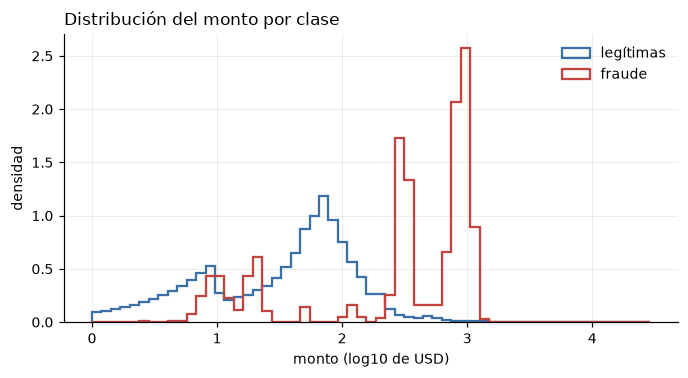

In [8]:
fig, ax = plt.subplots()
bins = np.linspace(0, np.log10(df["amt"].max()), 60)
for etiqueta, color in [(0, AZUL), (1, ROJO)]:
    ax.hist(
        np.log10(df.loc[df["is_fraud"] == etiqueta, "amt"]),
        bins=bins, density=True, histtype="step", linewidth=1.5, color=color,
        label="fraude" if etiqueta else "legítimas",
    )
ax.set_xlabel("monto (log10 de USD)")
ax.set_ylabel("densidad")
ax.legend(frameon=False)
ax.set_title("Distribución del monto por clase", loc="left")
plt.show()

In [9]:
cortes = [0, 10, 50, 100, 200, 500, 1000, np.inf]
etiquetas = ["<10", "10-50", "50-100", "100-200", "200-500", "500-1000", ">1000"]
rango = pd.cut(df["amt"], bins=cortes, labels=etiquetas)

por_rango = df.groupby(rango, observed=True).agg(
    transacciones=("is_fraud", "size"),
    fraudes=("is_fraud", "sum"),
)
por_rango["tasa_fraude_%"] = 100 * por_rango["fraudes"] / por_rango["transacciones"]
por_rango

,transacciones,fraudes,tasa_fraude_%
amt,,,
<10,335929,525,0.156
10-50,336370,1082,0.322
50-100,389483,45,0.012
100-200,172969,150,0.087
200-500,46293,2056,4.441
500-1000,11695,2699,23.078
>1000,3936,949,24.111


El monto es la variable que separa mejor las dos clases. La mediana de una transacción legítima es **47.28 USD** y la de un fraude **396.51 USD**, prácticamente ocho veces más. El histograma muestra dos distribuciones claramente distintas.

La tabla por rangos hace más concreto que, entre 500 y 1,000 USD **el 23% de las transacciones son fraude**, y por encima de 1,000 USD el 24%. También destaca una anomalía propia de que los datos sean sintéticos, el rango de 50 a 100 USD tiene una tasa de fraude casi nula (0.012%), mucho menor que el rango inferior. La relación entre monto y riesgo no es monótona, sino que el fraude se concentra en dos zonas: montos altos y montos muy pequeños.

Hay que notar además que el monto llega a 28,949 USD en transacciones legítimas pero se detiene en 1,376 USD en las fraudulentas, y que la distribución tiene una cola muy larga.

**Decisión:** se usará el **logaritmo del monto**, que comprime la cola larga y evita que unas pocas transacciones enormes dominen el modelo.

## 6. Comportamiento en el tiempo

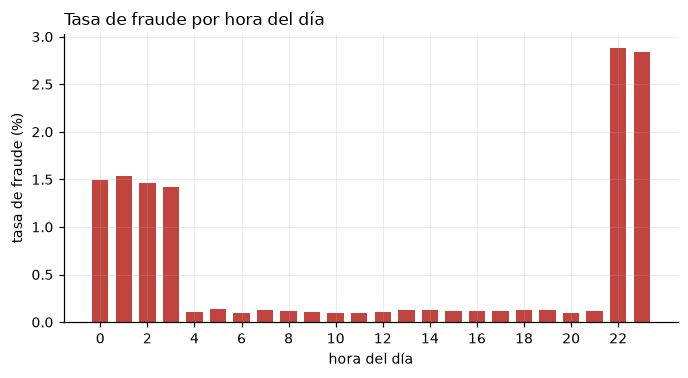

,transacciones,fraudes,tasa_%
hora,,,
22,66982,1931,2.883
23,67104,1904,2.837
1,42869,658,1.535
0,42502,635,1.494
2,42656,625,1.465
3,42769,609,1.424


In [10]:
df["hora"] = df["trans_date_trans_time"].dt.hour
df["dia_semana"] = df["trans_date_trans_time"].dt.dayofweek
df["mes"] = df["trans_date_trans_time"].dt.to_period("M")

por_hora = df.groupby("hora", observed=True).agg(
    transacciones=("is_fraud", "size"), fraudes=("is_fraud", "sum")
)
por_hora["tasa_%"] = 100 * por_hora["fraudes"] / por_hora["transacciones"]

fig, ax = plt.subplots()
ax.bar(por_hora.index, por_hora["tasa_%"], color=ROJO, width=0.7)
ax.set_xlabel("hora del día")
ax.set_ylabel("tasa de fraude (%)")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Tasa de fraude por hora del día", loc="left")
plt.show()

por_hora.sort_values("tasa_%", ascending=False).head(6)

tasa de fraude por día de la semana (%)
lunes       0.465
martes      0.584
miércoles   0.655
jueves      0.684
viernes     0.709
sábado      0.611
domingo     0.485

tasa mensual: mínimo 0.382% (2019-07), máximo 1.037% (2019-02)


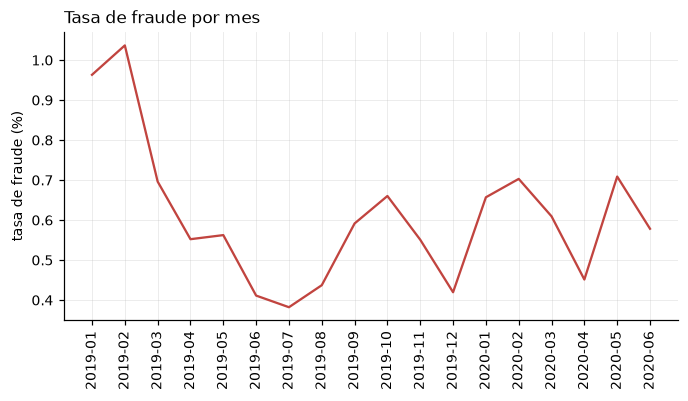

In [11]:
nombres = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
por_dia = df.groupby("dia_semana", observed=True)["is_fraud"].mean().mul(100)
por_dia.index = nombres
print("tasa de fraude por día de la semana (%)")
print(por_dia.round(3).to_string())

por_mes = df.groupby("mes", observed=True)["is_fraud"].mean().mul(100)
print(f"\ntasa mensual: mínimo {por_mes.min():.3f}% ({por_mes.idxmin()}), "
      f"máximo {por_mes.max():.3f}% ({por_mes.idxmax()})")

fig, ax = plt.subplots()
ax.plot(por_mes.index.astype(str), por_mes.values, color=ROJO, linewidth=1.5)
ax.set_ylabel("tasa de fraude (%)")
ax.tick_params(axis="x", rotation=90)
ax.set_title("Tasa de fraude por mes", loc="left")
plt.show()

La hora del día sí discrimina, y de forma muy marcada. **Las 22 y 23 horas concentran una tasa de 2.88% y 2.84%**, cinco veces el promedio general, y la madrugada de 0 a 3 horas ronda el 1.5%. El resto del día se mantiene por debajo del promedio.

El día de la semana apenas provoca cambios (de 0.47% el lunes a 0.71% el viernes), y la tasa mensual oscila sin una tendencia clara.

**Decisiones:** se incluye la **hora** y un indicador de **franja nocturna definido como 22:00–03:59**, que es la ventana que los datos señalan. El día de la semana se conserva porque no cuesta nada, aunque su señal sea débil. El mes se descarta, es específico del período observado y no generalizaría.

## 7. Categoría del comercio

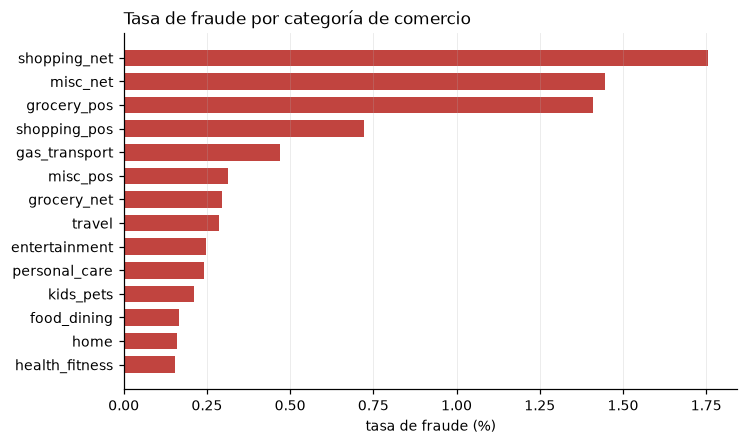

,transacciones,fraudes,tasa_%
category,,,
shopping_net,97543,1713,1.756
misc_net,63287,915,1.446
grocery_pos,123638,1743,1.410
shopping_pos,116672,843,0.723
gas_transport,131659,618,0.469
misc_pos,79655,250,0.314
grocery_net,45452,134,0.295
travel,40507,116,0.286
entertainment,94014,233,0.248


In [12]:
por_cat = df.groupby("category", observed=True).agg(
    transacciones=("is_fraud", "size"), fraudes=("is_fraud", "sum")
)
por_cat["tasa_%"] = 100 * por_cat["fraudes"] / por_cat["transacciones"]
por_cat = por_cat.sort_values("tasa_%")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.barh(por_cat.index.astype(str), por_cat["tasa_%"], color=ROJO, height=0.7)
ax.set_xlabel("tasa de fraude (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Tasa de fraude por categoría de comercio", loc="left")
plt.show()

por_cat.sort_values("tasa_%", ascending=False)

Las 14 categorías se ordenan en un rango amplio: de **1.76% en `shopping_net`** a **0.16% en `health_fitness`**, un factor de once entre la más y la menos riesgosa. Las tres primeras (`shopping_net`, `misc_net` y `grocery_pos`) acumulan la mayoría de los fraudes.

**Decisión:** `category` entra al modelo como **codificación one-hot** (14 columnas binarias), con el vocabulario fijado y guardado junto al modelo para que el servidor construya las mismas columnas en el mismo orden. La columna `merchant` se descarta, pues 693 comercios distintos generarían 693 columnas para una señal que `category` ya resume.

## 8. Geografía: distancia entre cliente y comercio

En el caso de uso se mencionó que se usaría la geolocalización como señal de fraude, así que se calcula la distancia entre el domicilio del titular y el comercio con la fórmula de haversine.

In [13]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distancia sobre la superficie de la Tierra, en kilómetros."""
    radio = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * radio * np.arcsin(np.sqrt(a))


df["distancia_km"] = haversine_km(df["lat"], df["long"], df["merch_lat"], df["merch_long"])

dist = df.groupby("is_fraud", observed=True)["distancia_km"].describe(percentiles=[0.5, 0.95])
dist.index = ["legítimas", "fraude"]
dist[["mean", "50%", "95%", "min", "max"]]

,mean,50%,95%,min,max
legítimas,76.114,78.233,120.497,0.022,152.118
fraude,76.268,77.932,120.156,0.739,144.523


Lastimosamente, el resultado es contundente y **contraintuitivo**. La distancia media es de 76.11 km en transacciones legítimas y 76.27 km en fraudes, con medianas de 78.23 y 77.93. Son cifras prácticamente idénticas, por lo que podemos decir que la distancia **no aporta ninguna capacidad de discriminación**.

La explicación está en el máximo, ninguna transacción supera los 152 km. Las coordenadas del comercio no son reales, sino un desplazamiento aleatorio alrededor del domicilio del titular. La variable mide el ruido del generador de datos, no un comportamiento de fraude.

**Decisión:** `distancia_km` **no se incluye** como variable del modelo. Habría añadido una columna sin información. Se buscará otra forma de incluir la señal geográfica más adelante.

Se revisa también la población de la ciudad del titular, para decidir si aporta algo.

In [14]:
decil = pd.qcut(df["city_pop"], 10, duplicates="drop")
por_pob = df.groupby(decil, observed=True).agg(
    transacciones=("is_fraud", "size"), fraudes=("is_fraud", "sum")
)
por_pob["tasa_%"] = 100 * por_pob["fraudes"] / por_pob["transacciones"]
print(por_pob.round(3).to_string())
print(f"\nrango de la tasa entre deciles: {por_pob['tasa_%'].min():.3f}% a {por_pob['tasa_%'].max():.3f}%")

                       transacciones  fraudes  tasa_%
city_pop                                             
(22.999, 260.0]               130386      806   0.618
(260.0, 566.0]                129089      739   0.572
(566.0, 964.0]                131445      705   0.536
(964.0, 1631.0]               129226      708   0.548
(1631.0, 2456.0]              129645      707   0.545
(2456.0, 4680.0]              128474      769   0.599
(4680.0, 10076.0]             131870      730   0.554
(10076.0, 42384.0]            127383      827   0.649
(42384.0, 186140.0]           130842      678   0.518
(186140.0, 2906700.0]         128315      837   0.652

rango de la tasa entre deciles: 0.518% a 0.652%


La tasa de fraude por decil de población se mueve entre **0.518% y 0.652%**, un rango estrecho y sin ninguna tendencia creciente ni decreciente. Vivir en una ciudad grande o pequeña no cambia el riesgo de forma apreciable.

**Decisión:** se conserva `city_pop` en escala logarítmica, por costo nulo, pero no se espera señal de ella. Su coeficiente en el modelo servirá para confirmarlo.

## 9. Historial de la tarjeta

Las variables anteriores describen la transacción por sí sola. Pero el fraude se reconoce sobre todo por el **contraste con lo habitual del cliente**; un consumo de 400 USD es normal para unos y alarmante para otros. Se construyen entonces dos comparaciones contra el pasado de cada tarjeta.

El cuidado indispensable aquí es no usar información del futuro. La media de gasto se calcula con una **media expansiva desplazada una posición**: para cada transacción se promedian únicamente los montos *anteriores* de esa misma tarjeta, nunca el propio ni los posteriores. Si se usara el promedio total de la tarjeta, el modelo estaría viendo datos que en producción no existen todavía, y las métricas saldrían falsamente buenas.

In [15]:
orden = df.sort_values(["cc_num", "trans_date_trans_time"])
grupo = orden.groupby("cc_num", observed=True)

# Media de los montos ANTERIORES de la misma tarjeta (nunca incluye la fila actual).
media_previa = grupo["amt"].apply(lambda s: s.expanding().mean().shift(1)).droplevel(0)
orden["razon_vs_media_previa"] = orden["amt"] / media_previa
orden["minutos_desde_anterior"] = grupo["trans_date_trans_time"].diff().dt.total_seconds() / 60

hist = orden.groupby("is_fraud", observed=True)[
    ["razon_vs_media_previa", "minutos_desde_anterior"]
].describe(percentiles=[0.5, 0.95])
hist.index = ["legítimas", "fraude"]
hist.round(2)

razon_vs_media_previa                                        minutos_desde_anterior                        \
                          count  mean   std   min   50%    95%     max                  count    mean     std   min   
legítimas         1,288,261.000 0.990 2.570 0.000 0.660  2.620 676.390          1,288,261.000 542.490 790.820 0.000   
fraude                7,431.000 6.980 6.840 0.010 5.230 17.090 160.150              7,431.000 355.390 607.280 0.020   

                                        
              50%       95%        max  
legítimas 277.050 1,905.820 22,357.850  
fraude     81.800 1,309.460 14,417.950

In [16]:
# Velocidad implícita: distancia entre los comercios de dos transacciones consecutivas
# de la misma tarjeta, dividida entre el tiempo transcurrido.
salto_km = haversine_km(
    grupo["merch_lat"].shift(1), grupo["merch_long"].shift(1),
    orden["merch_lat"], orden["merch_long"],
)
horas = orden["minutos_desde_anterior"] / 60
orden["velocidad_kmh"] = np.where(horas > 0, salto_km / horas, np.nan)

vel = orden.groupby("is_fraud", observed=True)["velocidad_kmh"].describe(percentiles=[0.5, 0.95, 0.99])
vel.index = ["legítimas", "fraude"]
print(vel[["mean", "50%", "95%", "99%"]].round(1).to_string())

umbral = 900  # velocidad de crucero de un avión comercial
sobre = orden.groupby("is_fraud", observed=True)["velocidad_kmh"].apply(lambda s: (s > umbral).mean() * 100)
sobre.index = ["legítimas", "fraude"]
print(f"\nporcentaje de transacciones con velocidad implícita > {umbral} km/h")
print(sobre.round(2).to_string())

             mean    50%       95%       99%
legítimas 185.900 19.900   369.300 1,930.300
fraude    750.400 64.300 1,684.400 9,555.500

porcentaje de transacciones con velocidad implícita > 900 km/h
legítimas   2.110
fraude      8.540


Las dos variables funcionan.

- **Razón contra la media previa.** Una transacción legítima gasta en promedio **0.99 veces** lo habitual de su tarjeta (mediana 0.66); un fraude gasta **6.98 veces** más (mediana 5.23). El percentil 95 de las legítimas es 2.62, mientras que el de los fraudes llega a 17.09.

- **Minutos desde la transacción anterior.** Los fraudes ocurren más pegados al movimiento previo (mediana de 82 minutos frente a 277 en las legítimas).

La velocidad implícita (cuántos kilómetros por hora habría tenido que viajar el titular entre dos compras consecutivas) también discrimina: la mediana de los fraudes es de 64.3 km/h contra 19.9 de las legítimas, y **el 8.54% de los fraudes exige más de 900 km/h frente al 2.11% de las legítimas**. Aquí sí aparece la señal geográfica que la distancia cliente-comercio no daba, porque lo informativo no es *dónde* ocurre la compra sino *qué tan lejos de la anterior* en poco tiempo.

**Decisiones:** se incluyen `razon_vs_media_previa` y `minutos_desde_anterior`, ambas calculadas solo con el pasado de la tarjeta. La geovelocidad **no entra al modelo** sino que se implementará como regla explícita en el servidor, con 900 km/h como umbral es una condición verificable y explicable ante un cliente o un auditor.

## 10. Columnas sin valor predictivo o con datos personales

Queda revisar las columnas restantes.

In [17]:
candidatas = ["trans_num", "first", "last", "street", "city", "zip", "job", "cc_num", "unix_time"]
pd.DataFrame({
    "valores_distintos": df[candidatas].nunique(),
    "por_tarjeta": [
        df.groupby("cc_num", observed=True)[c].nunique().max() if c != "cc_num" else 1
        for c in candidatas
    ],
})

,valores_distintos,por_tarjeta
trans_num,1296675,3123
first,352,1
last,481,1
street,983,1
city,894,1
zip,970,1
job,494,1
cc_num,983,1
unix_time,1274823,3123


In [18]:
print("tasa de fraude por género (%)")
print(df.groupby("gender", observed=True)["is_fraud"].mean().mul(100).round(3).to_string())

df["edad"] = (df["trans_date_trans_time"] - df["dob"]).dt.days / 365.25
edad = df.groupby("is_fraud", observed=True)["edad"].describe(percentiles=[0.5])
edad.index = ["legítimas", "fraude"]
print("\nedad del titular")
print(edad[["mean", "50%", "min", "max"]].round(1).to_string())

tasa de fraude por género (%)
gender
F   0.526
M   0.643

edad del titular
            mean    50%    min    max
legítimas 46.000 44.000 13.900 95.600
fraude    48.800 47.800 14.400 93.800


`first`, `last`, `street`, `city`, `zip` y `job` toman **un solo valor por tarjeta** (esperado, pues describen al titular, no a la transacción). Un modelo que las usara aprendería a reconocer clientes concretos en lugar de comportamientos de fraude, y fallaría con cualquier cliente nuevo. `trans_num` es un identificador único por fila y no contiene información.

El género y la edad sí muestran una diferencia pequeña pero consistente: 0.64% de fraude en hombres frente a 0.53% en mujeres, y una edad media de 48.8 años en los fraudes frente a 46.0 en las legítimas.

**Decisiones:** se descartan las columnas que identifican al titular y `trans_num`. Se conservan `gender` como indicador binario y `edad` calculada a la fecha de la transacción.

## 11. Conclusiones / Decisiones de Preprocesamiento

Todo lo anterior se resume en el contrato que implementará `scripts/prepare_dataset.py`. Cada decisión apunta a la sección que la respalda.

| # | Decisión | Origen |
|---|---|---|
| 1 | No se imputan ni deduplican filas | #3 |
| 2 | `trans_date_trans_time` es el único reloj; `unix_time` se descarta | #3 |
| 3 | El monto entra como **logaritmo** | #5 |
| 4 | Se incluyen `hora` y `es_noche` con la franja **22:00–03:59** | #6 |
| 5 | Se incluye `dia_semana` / `es_fin_semana`; el mes se descarta | #6 |
| 6 | `category` entra como **one-hot de 14 columnas** con vocabulario fijo; `merchant` se descarta | #7 |
| 7 | `distancia_km` **no se incluye** | #8 |
| 8 | `city_pop` entra en escala logarítmica, sin señal esperada | #8 |
| 9 | Se incluyen `razon_vs_media_previa` y `minutos_desde_anterior`, calculadas **solo con el pasado** de cada tarjeta | #9 |
| 10 | La **geovelocidad > 900 km/h** se implementa como regla del servidor, no como variable del modelo | #9 |
| 11 | Se incluyen `edad` y `genero`; se descartan las columnas que identifican al titular y `trans_num` | #10 |
| 12 | El desbalance se compensa al entrenar y la evaluación no usa exactitud | #4 |

Con esto queda definido qué debe producir el preprocesamiento. El entrenamiento y la evaluación del modelo se abordan en `02_modelado.ipynb`.